# STA572/570 Assessment 3 — Univariate & Box-Jenkins Forecasting
**Data:** USD/MYR Monthly Average Exchange Rate (Jan 2016 – Jul 2026), source: Bank Negara Malaysia

**Prepared by:** Nur Damia Izzati Binti Zuhaimi

## 1. Setup & Load Packages

In [ ]:
install.packages(c('forecast','tseries','urca','lmtest'))
library(forecast)
library(tseries)
library(urca)
library(lmtest)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
# Load the BNM exchange rate export.
# Download it from Bank Negara Malaysia and upload it to the Colab session
# (Files panel on the left) as 'exchange-rates.csv' before running this notebook.
file.exists("exchange-rates.csv")

## 2. Load, Clean & Aggregate Data
Note: the raw BNM export contains multiple currency blocks concatenated (USD block, then THB block, etc.). We extract only the first (USD/GBP/EUR...) block.

In [ ]:
raw <- readLines("exchange-rates.csv")

# Find the first separator row: strip all non-alphanumeric characters;
# a row that becomes empty marks the end of the first currency block
blank_row <- which(sapply(raw, function(l) nchar(gsub("[^A-Za-z0-9]", "", l)) == 0))[1]

cat("Blank row found at line:", blank_row, "\n")

data <- read.csv(text = raw[1:(blank_row-1)], header = TRUE)
colnames(data)[1] <- "Date"
data$Date <- as.Date(data$Date, format = "%d %b %Y")
data$USD  <- as.numeric(data$USD)
data <- data[order(data$Date), ]
str(data)

Warning message in readLines("exchange-rates.csv"):
“incomplete final line found on 'exchange-rates.csv'”


Blank row found at line: 2578 
'data.frame':	2576 obs. of  10 variables:
 $ Date  : Date, format: "2016-01-04" "2016-01-05" ...
 $ USD   : num  4.35 4.34 4.39 4.39 4.38 ...
 $ GBP   : num  6.42 6.38 6.43 6.41 6.41 ...
 $ EUR   : num  4.75 4.69 4.72 4.75 4.77 ...
 $ JPY100: num  3.65 3.64 3.7 3.74 3.7 ...
 $ CHF   : num  4.37 4.32 4.35 4.37 4.39 ...
 $ AUD   : num  3.14 3.12 3.11 3.09 3.08 ...
 $ CAD   : num  3.12 3.12 3.12 3.11 3.11 ...
 $ SGD   : num  3.05 3.05 3.06 3.06 3.05 ...
 $ HKD100: num  56.1 56 56.7 56.7 56.5 ...


In [ ]:
# Aggregate daily rates to monthly average
data$YearMonth <- format(data$Date, "%Y-%m")
monthly <- aggregate(USD ~ YearMonth, data = data, FUN = mean)
monthly <- monthly[order(monthly$YearMonth), ]
cat("Number of monthly observations:", nrow(monthly), "\n")

ts_data <- ts(monthly$USD, start = c(2016,1), frequency = 12)
print(ts_data)

Number of monthly observations: 127 
          Jan      Feb      Mar      Apr      May      Jun      Jul      Aug
2016 4.345474 4.183000 4.068587 3.900619 4.050405 4.081976 4.018526 4.024636
2017 4.458725 4.444556 4.437000 4.405184 4.313595 4.277316 4.289571 4.283591
2018 3.957490 3.913889 3.902468 3.886586 3.963667 3.998825 4.050773 4.091833
2019 4.116286 4.076000 4.079310 4.114818 4.170675 4.160694 4.124045 4.187881
2020 4.079143 4.162615 4.297841 4.352345 4.341188 4.275667 4.265864 4.188868
2021 4.037342 4.045667 4.110217 4.123052 4.127228 4.134943 4.200690 4.221450
2022 4.190600 4.187739 4.200678 4.269920 4.385100 4.403045 4.441300 4.466195
2023 4.328211 4.380139 4.466548 4.423750 4.523667 4.632700 4.593875 4.609105
2024 4.684529 4.770784 4.714925 4.767725 4.716476 4.709778 4.677295 4.414705
2025 4.473775 4.441858 4.433184 4.413119 4.262250 4.241737 4.236543 4.227643
2026 4.026810 3.912059 3.953850 3.976773 3.950411 4.079658 4.076167         
          Sep      Oct      Nov      De

## 3. Time Series Plot

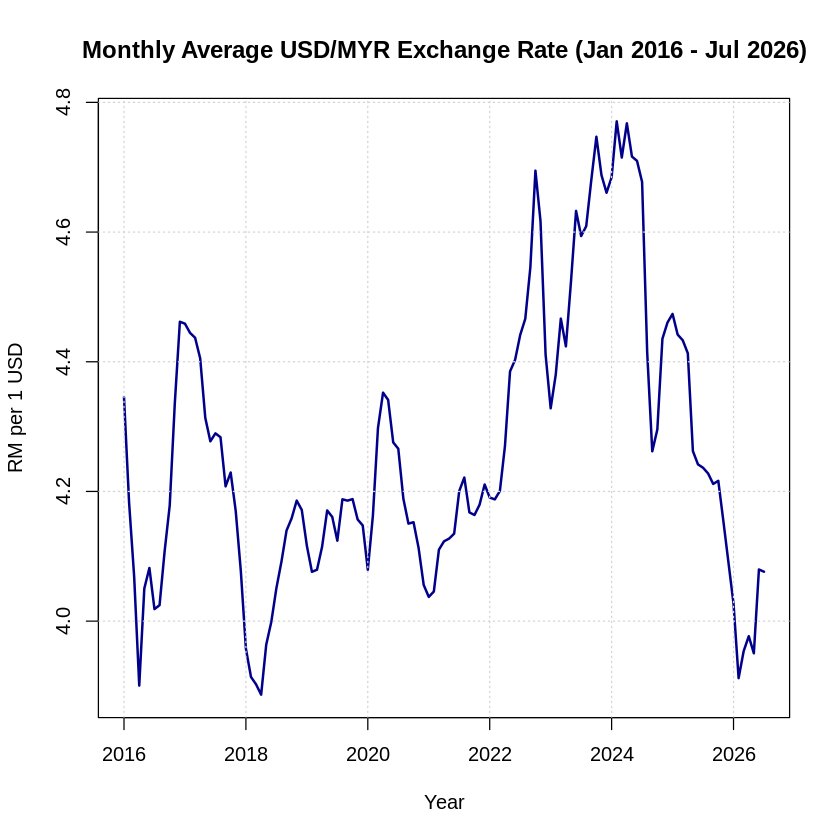

In [ ]:
plot(ts_data, main = "Monthly Average USD/MYR Exchange Rate (Jan 2016 - Jul 2026)",
     ylab = "RM per 1 USD", xlab = "Year", col = "darkblue", lwd = 2)
grid()

## 4. Decomposition (Additive & Multiplicative)

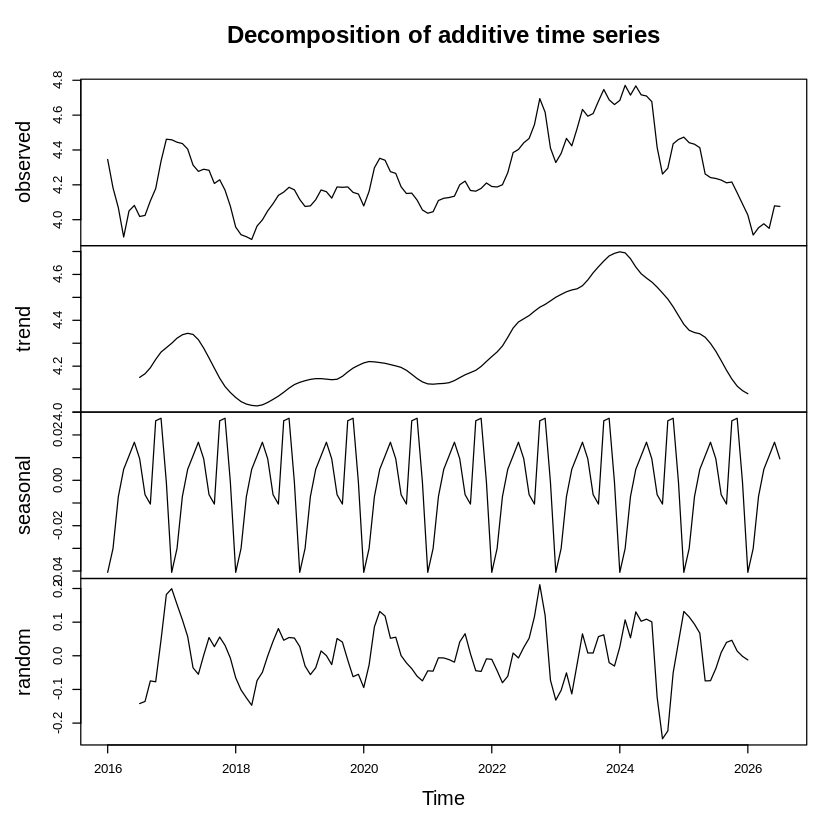

In [ ]:
dec_add <- decompose(ts_data, type = "additive")
plot(dec_add)

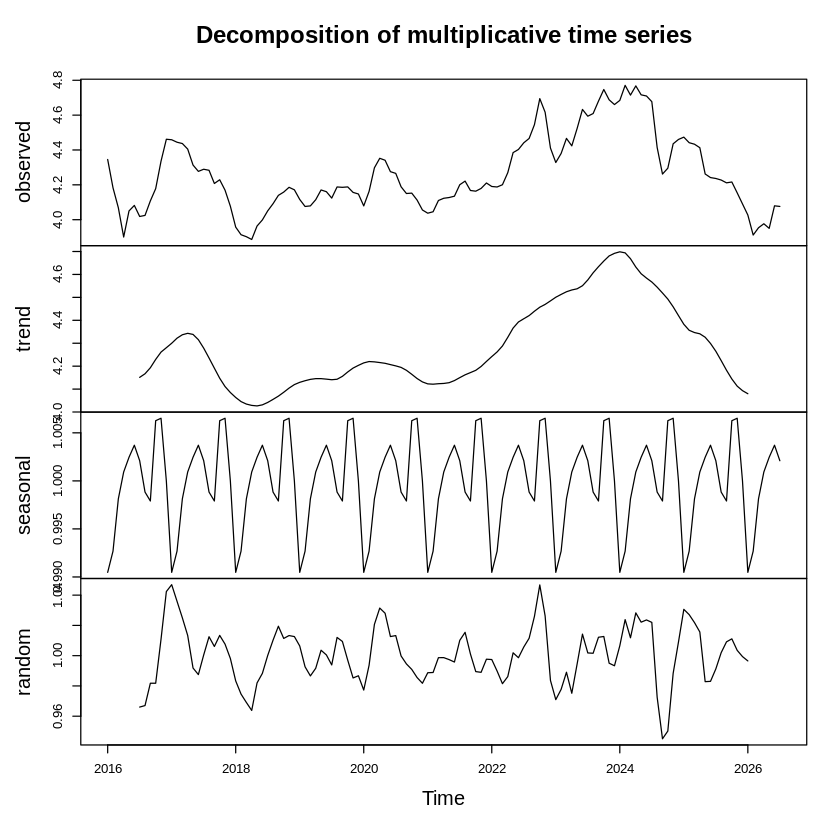

In [ ]:
dec_mult <- decompose(ts_data, type = "multiplicative")
plot(dec_mult)

## 5. Stationarity Check: ADF Test, ACF & PACF
We split the series into a **fitted (training)** part and a **hold-out (evaluation)** part — 70% / 30%, as per the assignment guideline.

In [ ]:
n <- length(ts_data)
n_fit <- round(n * 0.70)
fitted_part  <- window(ts_data, end   = time(ts_data)[n_fit])
holdout_part <- window(ts_data, start = time(ts_data)[n_fit + 1])
cat("Total obs:", n, "| Fitted:", length(fitted_part), "| Hold-out:", length(holdout_part), "\n")
cat("Fitted range:", start(fitted_part), "-", end(fitted_part), "\n")
cat("Hold-out range:", start(holdout_part), "-", end(holdout_part), "\n")

Total obs: 127 | Fitted: 89 | Hold-out: 38 
Fitted range: 2016 1 - 2023 5 
Hold-out range: 2023 6 - 2026 7 


In [ ]:
# ADF test on LEVEL data (fitted part)
adf.test(fitted_part)


	Augmented Dickey-Fuller Test

data:  fitted_part
Dickey-Fuller = -2.7306, Lag order = 4, p-value = 0.2755
alternative hypothesis: stationary


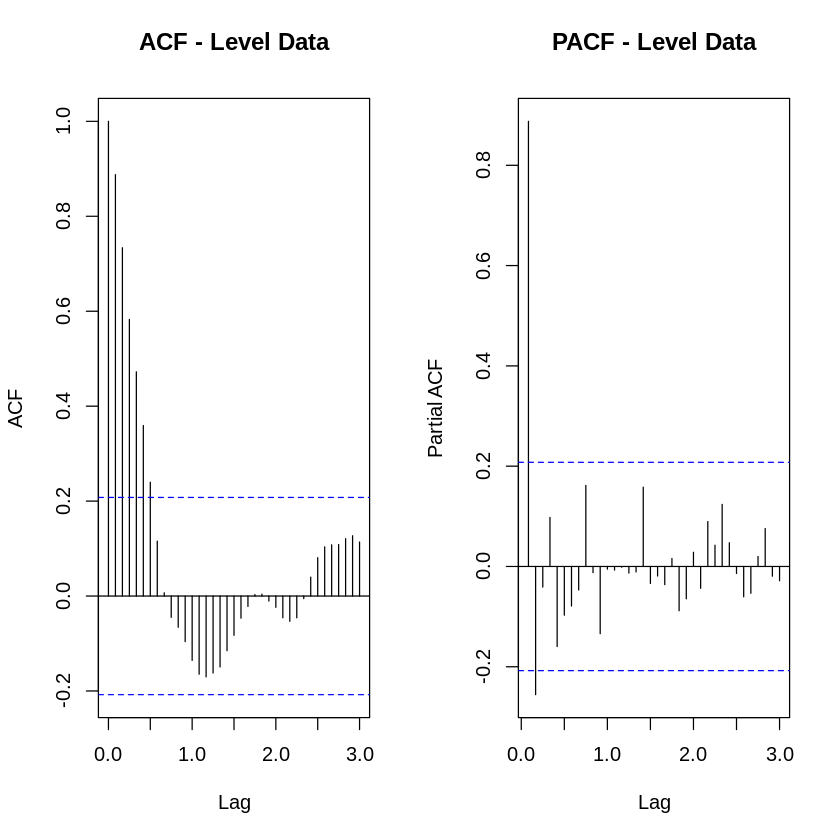

In [ ]:
par(mfrow = c(1,2))
acf(fitted_part, main = "ACF - Level Data", lag.max = 36)
pacf(fitted_part, main = "PACF - Level Data", lag.max = 36)

In [ ]:
# First differencing to achieve stationarity
diff_data <- diff(fitted_part)
adf.test(diff_data)

Warning message in adf.test(diff_data):
“p-value smaller than printed p-value”



	Augmented Dickey-Fuller Test

data:  diff_data
Dickey-Fuller = -4.2366, Lag order = 4, p-value = 0.01
alternative hypothesis: stationary


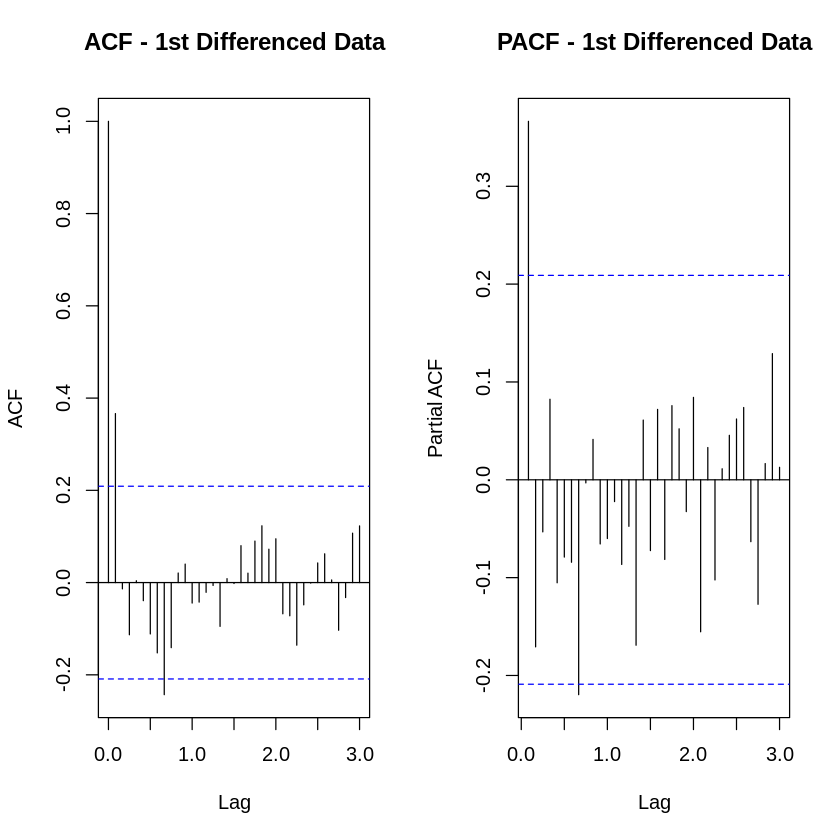

In [ ]:
par(mfrow = c(1,2))
acf(diff_data, main = "ACF - 1st Differenced Data", lag.max = 36)
pacf(diff_data, main = "PACF - 1st Differenced Data", lag.max = 36)

## 6. Section 5(a): Univariate Modelling Techniques
Three models chosen from Chapter 2: **Single Exponential Smoothing (SES)**, **Holt's Method**, and **ARRES** (Adaptive Response Rate Exponential Smoothing — no optimised parameter, uses fixed β as per course convention).

In [ ]:
# Find optimal parameters using TRAINING (fitted) data only
ses_train  <- HoltWinters(fitted_part, beta = FALSE, gamma = FALSE)
holt_train <- HoltWinters(fitted_part, gamma = FALSE)
cat("SES  optimal alpha  =", round(ses_train$alpha, 4), "\n")
cat("Holt optimal alpha  =", round(holt_train$alpha, 4), " beta =", round(holt_train$beta, 4), "\n")

SES  optimal alpha  = 1 
Holt optimal alpha  = 1  beta = 0.4851 


In [ ]:
# ARRES function (formula from Chapter 2 slides, fixed beta = 0.2)
arres_forecast <- function(y, beta = 0.2) {
  n <- length(y); F <- numeric(n+1); E <- numeric(n); AE <- numeric(n)
  F[1] <- y[1]; E[1] <- 0; AE[1] <- abs(y[1]-F[1])
  for (t in 1:n) {
    e_t <- y[t] - F[t]
    if (t == 1) { E[t] <- beta*e_t; AE[t] <- beta*abs(e_t) }
    else { E[t] <- beta*e_t + (1-beta)*E[t-1]; AE[t] <- beta*abs(e_t) + (1-beta)*AE[t-1] }
    alpha_t <- ifelse(AE[t]==0, 0, abs(E[t]/AE[t]))
    F[t+1] <- alpha_t*y[t] + (1-alpha_t)*F[t]
  }
  F
}

# Rolling ONE-STEP-AHEAD forecasts through the hold-out period (fair comparison for all 3 models)
y_full <- as.numeric(ts_data); n_fit <- length(fitted_part); h <- length(holdout_part)

ses_F <- numeric(length(y_full)+1); ses_F[1] <- y_full[1]
for (t in 1:length(y_full)) ses_F[t+1] <- ses_train$alpha*y_full[t] + (1-ses_train$alpha)*ses_F[t]
ses_onestep <- ses_F[(n_fit+1):(n_fit+h)]

holt_level <- numeric(length(y_full)); holt_trend <- numeric(length(y_full))
holt_level[1] <- y_full[1]; holt_trend[1] <- y_full[2]-y_full[1]
holt_fc <- numeric(length(y_full))
for (t in 2:length(y_full)) {
  holt_level[t] <- holt_train$alpha*y_full[t] + (1-holt_train$alpha)*(holt_level[t-1]+holt_trend[t-1])
  holt_trend[t] <- holt_train$beta*(holt_level[t]-holt_level[t-1]) + (1-holt_train$beta)*holt_trend[t-1]
  holt_fc[t] <- holt_level[t-1] + holt_trend[t-1]
}
holt_onestep <- holt_fc[(n_fit+1):(n_fit+h)]

arres_F <- arres_forecast(y_full, beta = 0.2)
arres_onestep <- arres_F[(n_fit+1):(n_fit+h)]

In [ ]:
mse  <- function(a,p) mean((a-p)^2)
mape <- function(a,p) mean(abs((a-p)/a))*100
actual_holdout <- y_full[(n_fit+1):(n_fit+h)]

results <- data.frame(
  Model = c("SES","Holt's","ARRES"),
  Parameter = c(paste0("alpha=",round(ses_train$alpha,3)),
                paste0("alpha=",round(holt_train$alpha,3),", beta=",round(holt_train$beta,3)),
                "beta=0.200 (fixed)"),
  MSE  = c(mse(actual_holdout, ses_onestep), mse(actual_holdout, holt_onestep), mse(actual_holdout, arres_onestep)),
  MAPE = c(mape(actual_holdout, ses_onestep), mape(actual_holdout, holt_onestep), mape(actual_holdout, arres_onestep))
)
print(results)
cat("\nBest univariate model:", results$Model[which.min(results$MSE)], "\n")

   Model           Parameter         MSE     MAPE
1    SES             alpha=1 0.006020337 1.276620
2 Holt's alpha=1, beta=0.485 0.007141364 1.425090
3  ARRES  beta=0.200 (fixed) 0.011500656 1.923143

Best univariate model: SES 


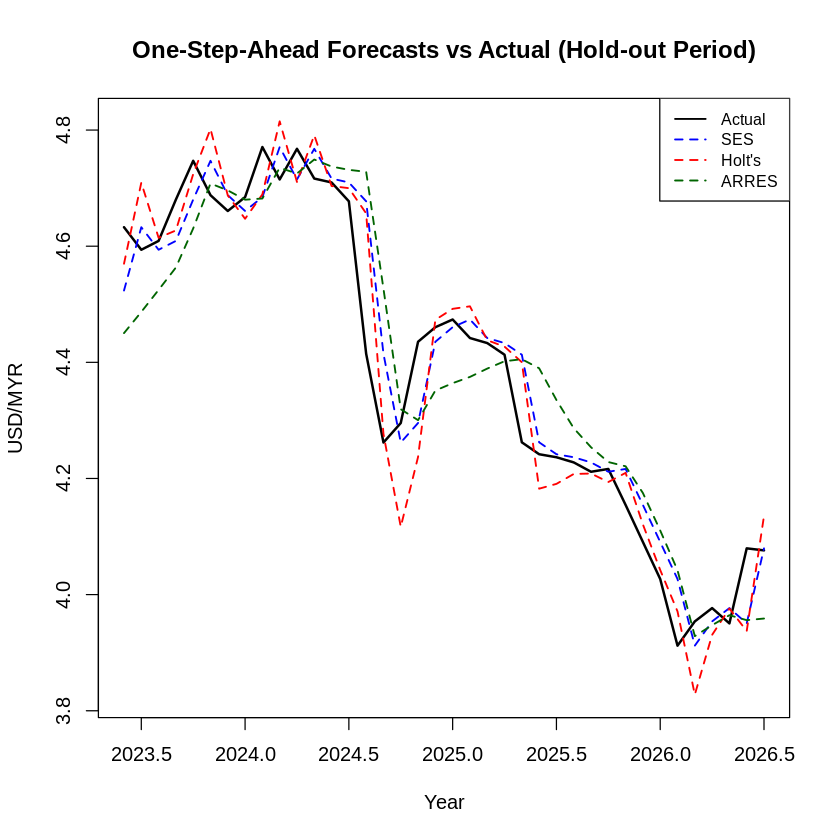

In [ ]:
holdout_time <- as.numeric(time(holdout_part))
plot(holdout_time, actual_holdout, type="l", lwd=2, col="black",
     main="One-Step-Ahead Forecasts vs Actual (Hold-out Period)",
     xlab="Year", ylab="USD/MYR",
     ylim=range(c(actual_holdout, ses_onestep, holt_onestep, arres_onestep)))
lines(holdout_time, ses_onestep, col="blue", lty=2, lwd=1.5)
lines(holdout_time, holt_onestep, col="red", lty=2, lwd=1.5)
lines(holdout_time, arres_onestep, col="darkgreen", lty=2, lwd=1.5)
legend("topright", legend=c("Actual","SES","Holt's","ARRES"),
       col=c("black","blue","red","darkgreen"), lty=c(1,2,2,2), lwd=1.5, cex=0.8)

In [ ]:
# One-step-ahead forecast for the NEXT period (Aug 2026), refit each model on the FULL series
next_ses  <- ses_train$alpha*y_full[length(y_full)] + (1-ses_train$alpha)*ses_F[length(y_full)]
next_holt <- holt_level[length(y_full)] + holt_trend[length(y_full)]
next_arres <- arres_F[length(y_full)+1]
cat("One-step-ahead forecast for Aug 2026:\n")
cat("  SES:", round(next_ses,4), "| Holt's:", round(next_holt,4), "| ARRES:", round(next_arres,4), "\n")
cat("=> Best model (SES) forecast for Aug 2026: RM", round(next_ses,4), "per USD\n")

One-step-ahead forecast for Aug 2026:
  SES: 4.0762 | Holt's: 4.1033 | ARRES: 3.9923 
=> Best model (SES) forecast for Aug 2026: RM 4.0762 per USD


## 7. Section 5(b): ARIMA/SARIMA — Box-Jenkins Methodology
### Part A: Model Identification
From the ACF/PACF of the differenced series: ACF cuts off after lag 1, PACF cuts off after lag 1 (both significant at lag 1) → suggests an ARMA(1,1)-type structure. Five candidate models (d = 1, confirmed by ADF test) are proposed:

In [ ]:
candidates <- list(
  "ARIMA(1,1,0)" = c(1,1,0),
  "ARIMA(0,1,1)" = c(0,1,1),
  "ARIMA(1,1,1)" = c(1,1,1),
  "ARIMA(2,1,0)" = c(2,1,0),
  "ARIMA(0,1,2)" = c(0,1,2)
)
candidates

$`ARIMA(1,1,0)`
[1] 1 1 0

$`ARIMA(0,1,1)`
[1] 0 1 1

$`ARIMA(1,1,1)`
[1] 1 1 1

$`ARIMA(2,1,0)`
[1] 2 1 0

$`ARIMA(0,1,2)`
[1] 0 1 2

### Part B: Model Estimation & Validation

In [ ]:
results_list <- list(); model_objs <- list()
for (nm in names(candidates)) {
  ord <- candidates[[nm]]
  fit <- Arima(fitted_part, order = ord)
  lb <- Box.test(residuals(fit), lag = 12, type = "Ljung-Box", fitdf = sum(ord[c(1,3)]))
  results_list[[nm]] <- data.frame(Model = nm, AIC = fit$aic, BIC = BIC(fit), LjungBox_p = lb$p.value)
  model_objs[[nm]] <- fit
}
results_df <- do.call(rbind, results_list); rownames(results_df) <- NULL
print(results_df)

best_name <- results_df$Model[which.min(results_df$AIC)]
cat("\nBest model (lowest AIC):", best_name, "\n")

         Model       AIC       BIC LjungBox_p
1 ARIMA(1,1,0) -231.6304 -226.6757  0.4438862
2 ARIMA(0,1,1) -233.4933 -228.5387  0.6670313
3 ARIMA(1,1,1) -231.8795 -224.4475  0.6271608
4 ARIMA(2,1,0) -232.5088 -225.0768  0.6809440
5 ARIMA(0,1,2) -232.0923 -224.6603  0.6558746

Best model (lowest AIC): ARIMA(0,1,1) 


In [ ]:
best_fit <- model_objs[[best_name]]
summary(best_fit)

lb_best <- Box.test(residuals(best_fit), lag = 12, type = "Ljung-Box")
cat("\nLjung-Box test on best model residuals: p-value =", round(lb_best$p.value, 4), "\n")
cat("p-value > 0.05  =>  FAIL TO REJECT H0  =>  residuals ARE white noise (good model fit)\n")

Series: fitted_part 
ARIMA(0,1,1) 

Coefficients:
         ma1
      0.4364
s.e.  0.0958

sigma^2 = 0.003976:  log likelihood = 118.75
AIC=-233.49   AICc=-233.35   BIC=-228.54

Training set error measures:
                      ME      RMSE      MAE        MPE     MAPE    MASE
Training set 0.001955368 0.0623398 0.045894 0.03768729 1.085911 0.24893
                    ACF1
Training set 0.007762252


Ljung-Box test on best model residuals: p-value = 0.7441 
p-value > 0.05  =>  FAIL TO REJECT H0  =>  residuals ARE white noise (good model fit)



	Ljung-Box test

data:  Residuals from ARIMA(0,1,1)
Q* = 13.368, df = 17, p-value = 0.7112

Model df: 1.   Total lags used: 18



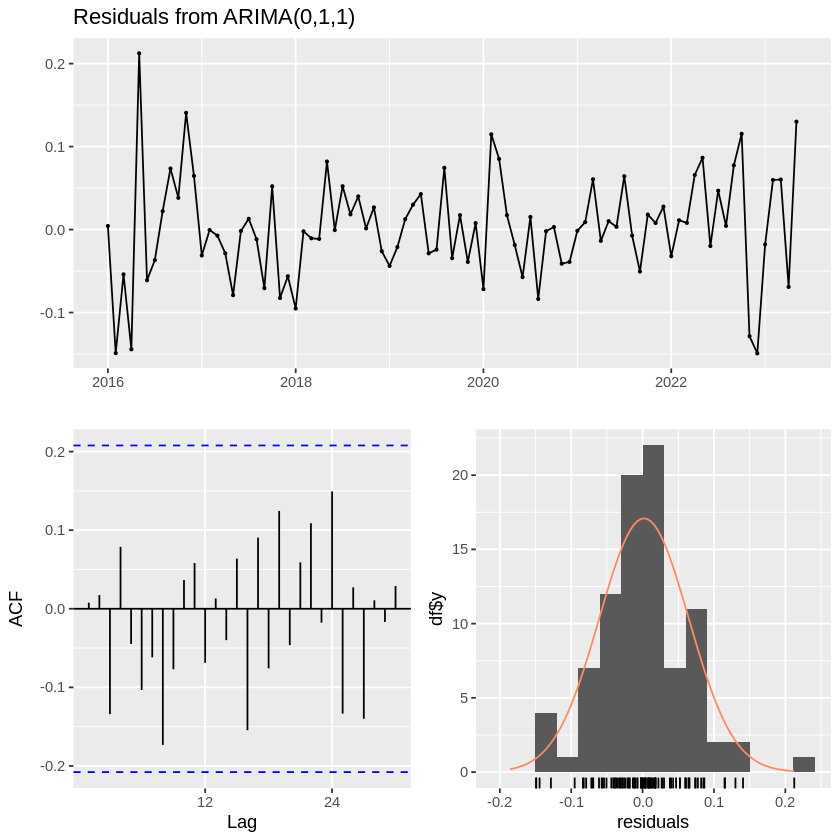

In [ ]:
checkresiduals(best_fit)

### Forecast Using Best ARIMA Model, Compared Against Hold-out

In [ ]:
# Rolling ONE-STEP-AHEAD forecast (fixed parameters, updated with actual data) — fair comparison basis
onestep_arima <- numeric(h)
for (i in 1:h) {
  data_upto_t <- window(ts_data, end = time(ts_data)[n_fit + i - 1])
  refit <- Arima(data_upto_t, model = best_fit)
  onestep_arima[i] <- forecast(refit, h = 1)$mean[1]
}

arima_mse  <- mse(actual_holdout, onestep_arima)
arima_mape <- mape(actual_holdout, onestep_arima)
cat("ARIMA(0,1,1) one-step-ahead: MSE =", round(arima_mse,5), " MAPE =", round(arima_mape,4), "%\n")

ARIMA(0,1,1) one-step-ahead: MSE = 0.00538  MAPE = 1.3045 %


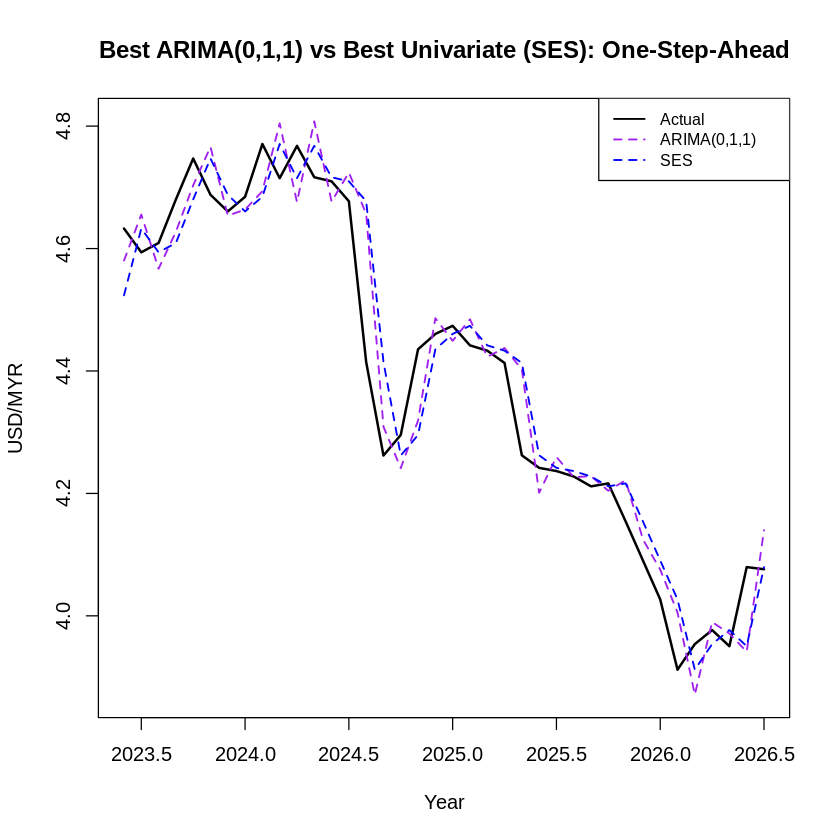

In [ ]:
plot(holdout_time, actual_holdout, type="l", lwd=2, col="black",
     main="Best ARIMA(0,1,1) vs Best Univariate (SES): One-Step-Ahead",
     xlab="Year", ylab="USD/MYR", ylim=range(c(actual_holdout, onestep_arima, ses_onestep)))
lines(holdout_time, onestep_arima, col="purple", lty=2, lwd=1.5)
lines(holdout_time, ses_onestep, col="blue", lty=2, lwd=1.5)
legend("topright", legend=c("Actual","ARIMA(0,1,1)","SES"), col=c("black","purple","blue"), lty=c(1,2,2), lwd=1.5, cex=0.8)

## 8. Final Comparison: Best ARIMA vs Best Univariate Model

In [ ]:
comparison <- data.frame(
  Model = c("ARIMA(0,1,1)", "SES (best univariate)"),
  MSE   = c(arima_mse, results$MSE[results$Model=="SES"]),
  MAPE  = c(arima_mape, results$MAPE[results$Model=="SES"])
)
print(comparison)

                  Model         MSE     MAPE
1          ARIMA(0,1,1) 0.005379953 1.304456
2 SES (best univariate) 0.006020337 1.276620


In [ ]:
# One-step-ahead forecast for Aug 2026, refit on FULL data
full_fit <- Arima(ts_data, order = c(0,1,1))
fc_next <- forecast(full_fit, h = 1)
cat("ARIMA(0,1,1) forecast for Aug 2026:", round(fc_next$mean[1],4),
    " [95% CI:", round(fc_next$lower[1,2],4), "-", round(fc_next$upper[1,2],4), "]\n")

ARIMA(0,1,1) forecast for Aug 2026: 4.0506  [95% CI: 3.9206 - 4.1807 ]
